## Лабораторная работа №1 | Вариант 4

Выполнил: 

### 1. Numpy

In [2]:
import numpy as np

1. Найти индексы не нулевых элементов массива [1,2,0,0,4,0]

In [3]:
arr = np.array([1, 2, 0, 0, 4, 0])
indices = np.nonzero(arr)[0]
print(indices)

[0 1 4]


2. Создайте единичную матрицу размером 3х3

In [4]:
identity = np.eye(3, dtype=int)
print(identity)

[[1 0 0]
 [0 1 0]
 [0 0 1]]


3. Создайте матрицу-шахматную доску 8х8 используя функцию `tile`

In [5]:
print(np.tile([[0, 1], [1, 0]], reps=(4, 4)))

[[0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]]


4. Дан 1D массив, удалите все элементы которые входят в диапазон `[3, 8]` inplace

In [8]:
arr = np.array([0, 4, 4, 2, 1, 4, 8, 7, 10, 15])
old_id = id(arr)

wrindex = 0
for reindex in range(arr.size):
    if not 3 <= arr[reindex] <= 8:
        arr[wrindex] = arr[reindex]
        wrindex += 1

arr.resize(wrindex, refcheck=False)
print(arr)


[ 0  2  1 10 15]


5. Создайте случайный вектор размером 10 элементов и замените максимальный элемент на 0

In [10]:
a = np.random.rand(10)
print(a)
a[a.argmax()] = 0
print(a)

[0.10983607 0.06274664 0.52893142 0.77747361 0.44952004 0.48569433
 0.20839031 0.63574871 0.52241509 0.37704213]
[0.10983607 0.06274664 0.52893142 0.         0.44952004 0.48569433
 0.20839031 0.63574871 0.52241509 0.37704213]


6. Как распечатать все значения в массиве?

In [12]:
a = np.arange(100)
with np.printoptions(threshold=np.inf):
    print(a)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]


7. Рассмотрим случайный вектор с формой 100х2, представляющей координаты, и найдем расстояния от точки к точке

In [ ]:
p = np.random.rand(100, 2)
d = np.zeros((100, 100))

for i in range(100):
    for j in range(100):
        d[i, j] = np.sqrt(np.sum((p[i] - p[j]) ** 2))

print(d[:5, :5])


8. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [15]:
a = np.array([1.2, -2.8, 3.5], dtype=np.float32)
b = a.astype(np.int32)
a.dtype = np.int32
a[:] = b
print(a, a.dtype)

[ 1 -2  3] int32


9. Как прочитать заданный файл?
```
1, 2, 3, 4, 5
6,  ,  , 7, 8
 ,  , 9,10,11
```

In [48]:
from io import StringIO

s = "1, 2, 3, 4, 5\n6,  ,  , 7, 8\n ,  , 9,10,11"
a = np.genfromtxt(StringIO(s), delimiter=",", autostrip=True)
# Если данные в файле csv, то можно использовать np.genfromtxt("file.csv", delimiter=",", autostrip=True)
print(a)


[[ 1.  2.  3.  4.  5.]
 [ 6. nan nan  7.  8.]
 [nan nan  9. 10. 11.]]


10. Какой эквивалент enumerate для numpy массивов?

In [17]:
a = np.array([[10, 20], [30, 40]])
for i, x in np.ndenumerate(a):
    print(i, x)


(0, 0) 10
(0, 1) 20
(1, 0) 30
(1, 1) 40


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Файл: `russian-housing-market.csv`

```
price_doc - Цена продажи
id - Id транзакции
timestamp - Дата транзакции
full_sq - суммарная площадь в квадратных метрах, включая лоджию, валконы и отдельные нежилые помещения
life_sq - жилая площаль в квадратных метрах, исключая лоджии, балконы и прочие нежилые помещения
floor - для апартаментов, этаж помещения
max_floor - количество этажей в здании
material - материал стен
build_year - год постройки
num_room - количество жилых комнат
kitch_sq - площадь кухни
state - состояние апартаментов
product_type - покупка или инвестиция собственника-арендатора
sub_area - название района
```

In [19]:
import pandas as pd

In [20]:
# Load dataset here
df = pd.read_csv("russian-housing-market.csv", parse_dates=["timestamp"])
print(df.head())


   id  timestamp  full_sq  life_sq  floor  max_floor  material  build_year  \
0   1 2011-08-20       43     27.0    4.0        NaN       NaN         NaN   
1   2 2011-08-23       34     19.0    3.0        NaN       NaN         NaN   
2   3 2011-08-27       43     29.0    2.0        NaN       NaN         NaN   
3   4 2011-09-01       89     50.0    9.0        NaN       NaN         NaN   
4   5 2011-09-05       77     77.0    4.0        NaN       NaN         NaN   

   num_room  kitch_sq  state product_type           sub_area  price_doc  
0       NaN       NaN    NaN   Investment           Bibirevo    5850000  
1       NaN       NaN    NaN   Investment  Nagatinskij Zaton    6000000  
2       NaN       NaN    NaN   Investment     Tekstil'shhiki    5700000  
3       NaN       NaN    NaN   Investment             Mitino   13100000  
4       NaN       NaN    NaN   Investment          Basmannoe   16331452  


1. Посчитайте количество записей в датасете с отсутствующей информацией о жилой площади жилого помещения

In [21]:
print(df["life_sq"].isna().sum())

6383


2. Предложите способ заменить отсутствующие значения из пункта 1 и реализуйте его. Способ нужно аргументировать(сказать почему это достаточно хорошее приближение)

In [22]:
df2 = df.copy()
a = df2["life_sq"].median()
df2["life_sq"] = df2["life_sq"].fillna(a)
print(a)
print("Осталось пропусков:", df2["life_sq"].isna().sum())

30.0
Осталось пропусков: 0


Можно заполнить пропуски медианой: она меньше зависит от выбросов, чем среднее.Это позволит сохранить записи с отсутствующими данными (но без учета особенностей квартир). Заполненная таблица — df2, остальные задания считаются по исходной df.

3. Какие значения имеет 25, 50 и 75 перцентили полной площади помещения

In [23]:
print(df["full_sq"].quantile([0.25, 0.5, 0.75]))

0.25    38.0
0.50    49.0
0.75    63.0
Name: full_sq, dtype: float64


4. Посчитайте среднюю стоимость продажи помещений с общей площадью от 50 до 70 квадратных метров

In [24]:
a = df[df["full_sq"].between(50, 70)]
print(round(a["price_doc"].mean(), 2))

7243041.19


5. Какая максимальная этажность здания представлена в датасете

In [25]:
print(df["max_floor"].max())

117.0


6. Выявите район с самым дорогим жильем

In [27]:
a = df.groupby("sub_area")["price_doc"].mean()
print(a.idxmax())
print("Средняя цена:", round(a.max(), 2))

Hamovniki
Средняя цена: 20116565.54


7. Посчитайте среднюю стоимость за квадратный метр жилья в Митино(Mitino)

In [28]:
a = df[(df["sub_area"] == "Mitino") & (df["full_sq"] > 0)]
print(round((a["price_doc"] / a["full_sq"]).mean(), 2))

171841.4


8. Посчитайте среднюю площадь комнаты в Бибирево

In [29]:
a = df[df["sub_area"] == "Bibirevo"]
a = a[(a["num_room"] > 0) & (a["life_sq"] > 0) & (a["life_sq"] <= a["full_sq"])]
print(round((a["life_sq"] / a["num_room"]).mean(), 2))

15.98


9. Проанализируйте есть ли разница в цене между квартирами на 1 и 9 этажах

In [30]:
a = df[df["floor"].isin([1, 9])]
print(a.groupby("floor")["price_doc"].agg(["count", "mean", "median"]).round(2))



b = a.groupby("floor")["price_doc"].mean()
print("Разница средних цен:", round(b[9] - b[1], 2))

       count        mean     median
floor                              
1.0     2002  5739379.59  5569575.0
9.0     1843  6937582.58  6400000.0
Разница средних цен: 1198203.0


10. Найдите минимальную стоимость квартиры с жилой площадью не менее 60 квадратных метров, не менее чем 3мя комнатами и не ниже чем на 5 этаже

In [31]:
a = df[(df["life_sq"] >= 60) & (df["num_room"] >= 3) & (df["floor"] >= 5)]
print(a["price_doc"].min())

1000000


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

In [32]:
import matplotlib.pyplot as plt

1. Как менялась средняя цена квартиры в Нагатинском Затоне(Nagatinski Zaton) с течением времени

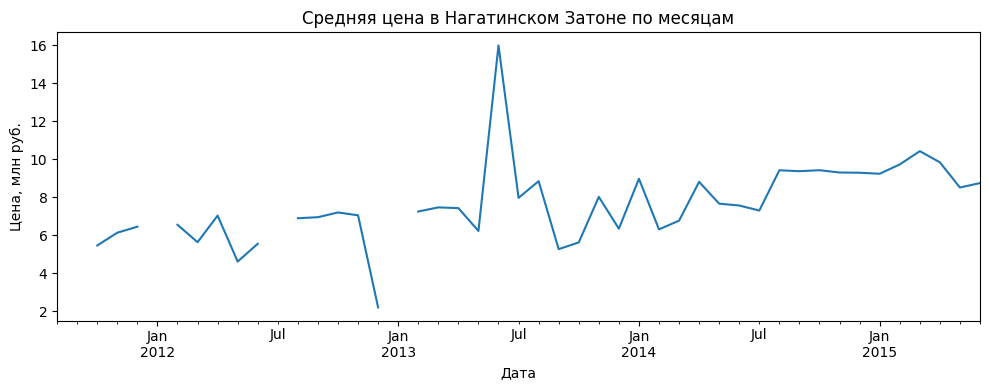

In [33]:
a = df[df["sub_area"] == "Nagatinskij Zaton"]
a = a.resample("MS", on="timestamp")["price_doc"].mean()
(a / 1000000).plot(figsize=(10, 4))
plt.title("Средняя цена в Нагатинском Затоне по месяцам")
plt.xlabel("Дата")
plt.ylabel("Цена, млн руб.")
plt.tight_layout()
plt.show()

2. Постройте гистограмму распределения цен на квартиры с общей площадью более 50 кв.метров

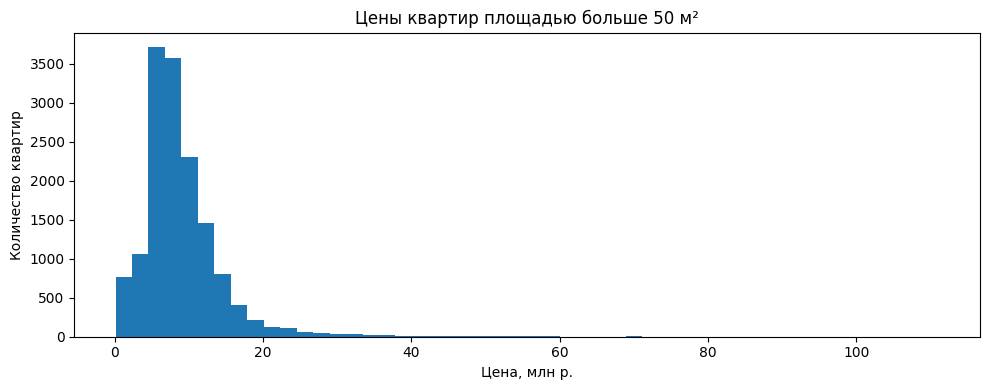

In [34]:
a = df.loc[df["full_sq"] > 50, "price_doc"]
(a / 1000000).plot.hist(bins=50, figsize=(10, 4))
plt.title("Цены квартир площадью больше 50 м²")
plt.xlabel("Цена, млн р.")
plt.ylabel("Количество квартир")
plt.tight_layout()
plt.show()


3. Визуализируйте количество проданных квартир в разных районах

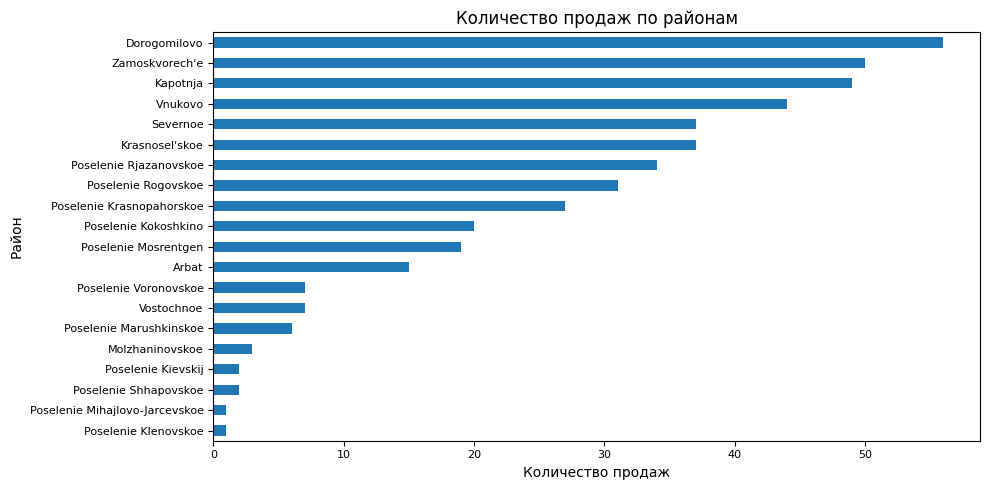

In [38]:
a = df["sub_area"].value_counts().sort_values().head(20)
a.plot.barh(figsize=(10, 5), fontsize=8)
plt.title("Количество продаж по районам")
plt.xlabel("Количество продаж")
plt.ylabel("Район")
plt.tight_layout()
plt.show()

4. Постройте box plot отображающий распределение полных площадей квартир в Басманном районе

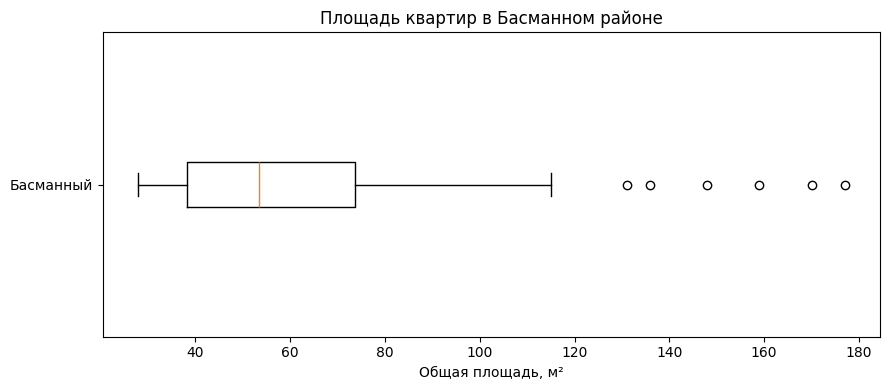

In [39]:
a = df.loc[df["sub_area"] == "Basmannoe", "full_sq"]
plt.figure(figsize=(9, 4))
plt.boxplot(a.dropna(), vert=False)
plt.title("Площадь квартир в Басманном районе")
plt.xlabel("Общая площадь, м²")
plt.yticks([1], ["Басманный"])
plt.tight_layout()
plt.show()

5. Визуализируйте зависимость средней стоимости квартир в зависимости от этажа

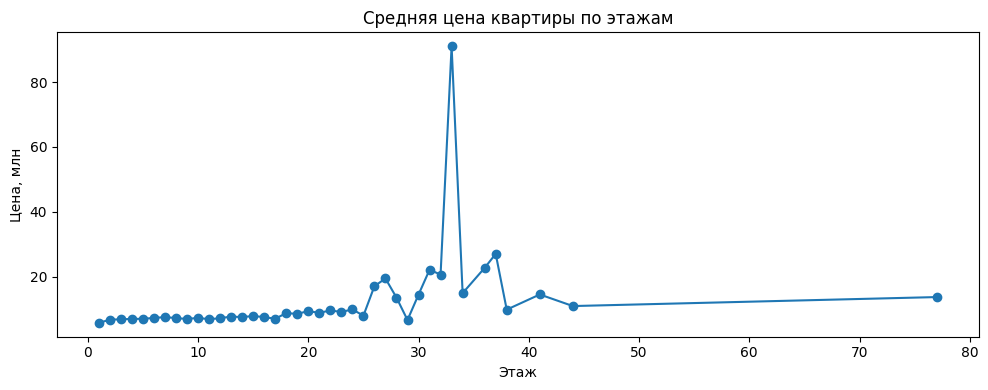

In [41]:
a = df[df["floor"] >= 1].groupby("floor")["price_doc"].mean()
(a / 1000000).plot(style="o-", figsize=(10, 4))
plt.title("Средняя цена квартиры по этажам")
plt.xlabel("Этаж")
plt.ylabel("Цена, млн")
plt.tight_layout()
plt.show()


6. Покажите как меняется средняя площадь квартир в зависимости от района

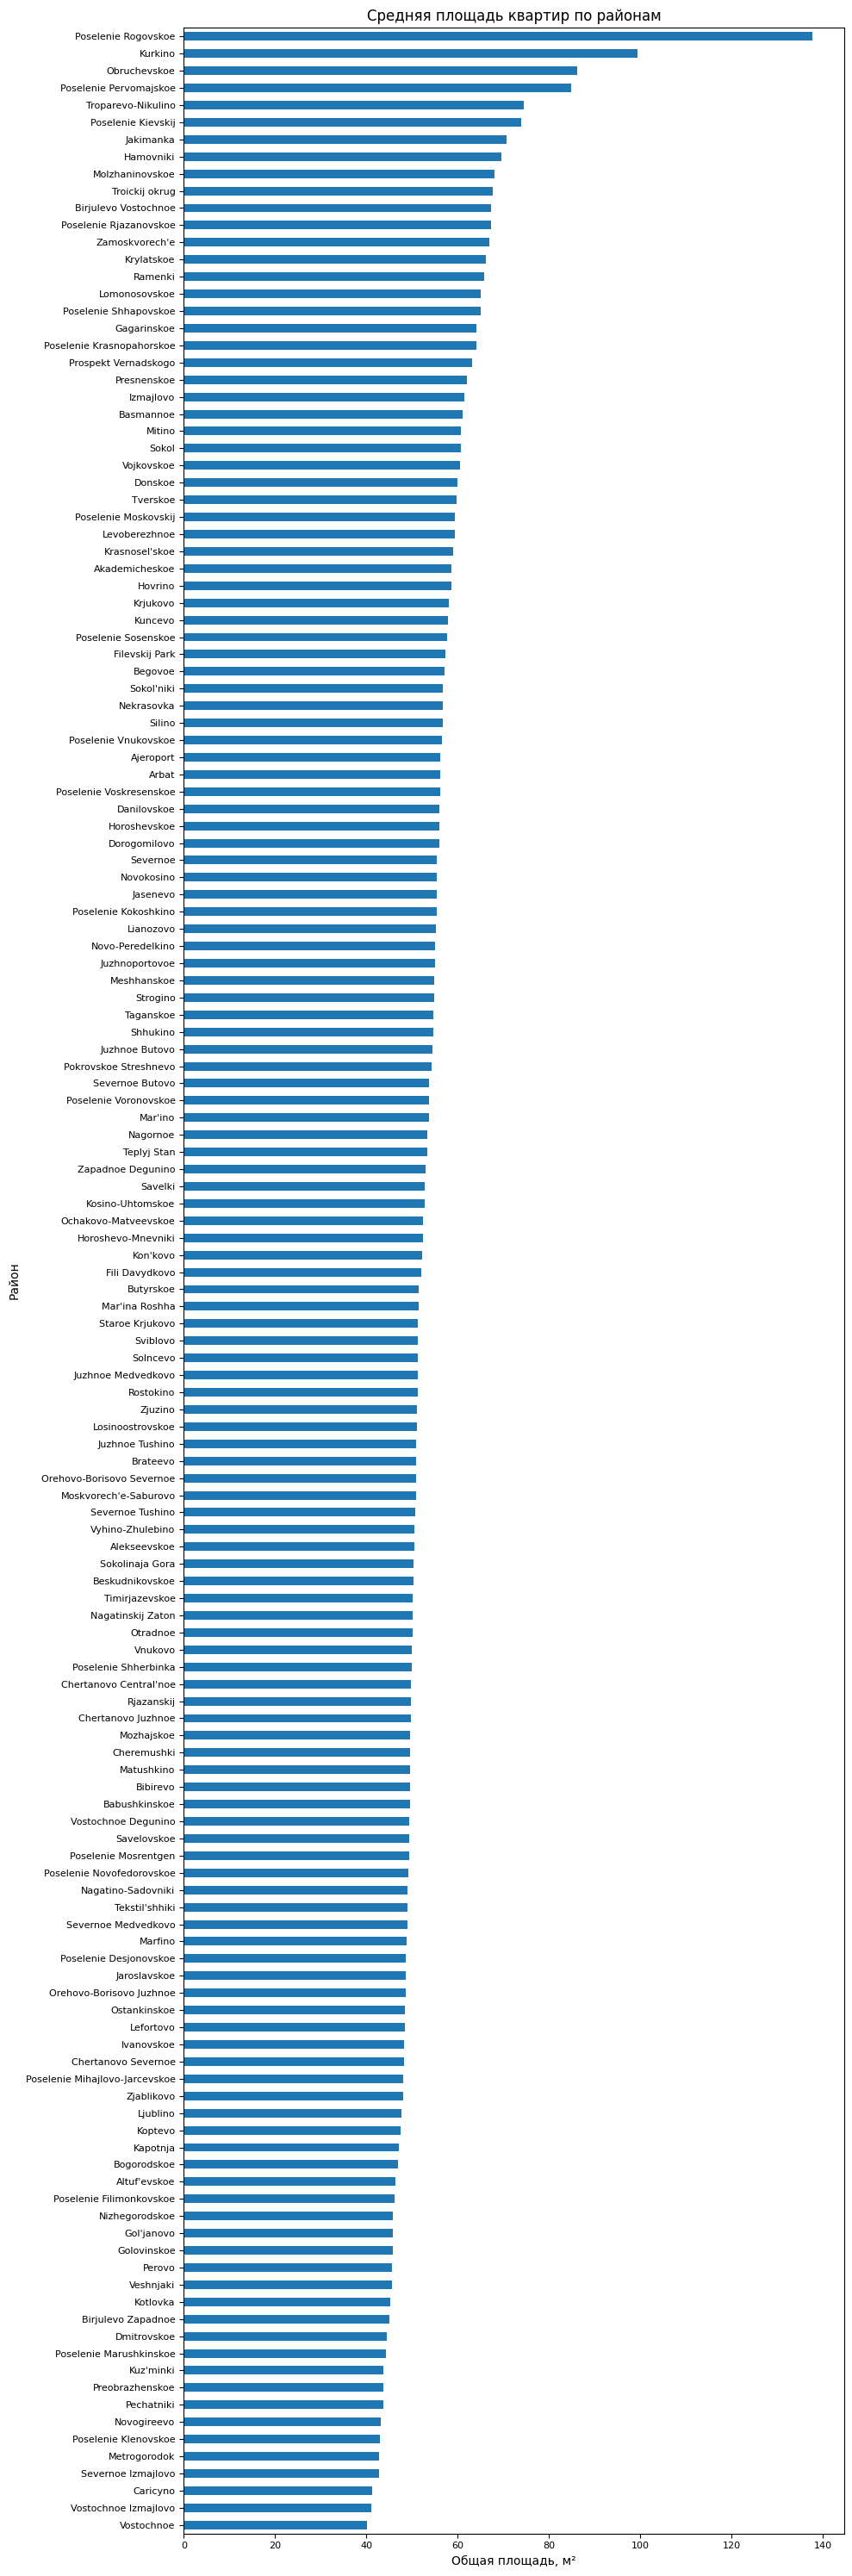

In [47]:
a = df.groupby("sub_area")["full_sq"].mean().sort_values()
a.plot.barh(figsize=(10, 30), fontsize=8)
plt.title("Средняя площадь квартир по районам")
plt.xlabel("Общая площадь, м²")
plt.ylabel("Район")
plt.tight_layout()
plt.show()

7. Постройте график изменения медианной цены на квартиру менее 50 кв. метров за период с 2011 до 2014 года*

\* Задание на доп. балл

In [ ]:
# :(